In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('bmh')

## Pelota de Vóley (Referencia Benja)

### Parámetros

In [18]:
#Los comentarios para la explicación del código sólo se añadieron para este balón 
# ya que el procedimiento para los demás balones es el mismo.

ARCHIVO = "datos/voley.csv"

m    = 0.279      # masa del balón [kg]
D    = 0.203      # diámetro del balón [m]
A    = np.pi*(D/2)**2   # área transversal [m^2]
C    = 0.4       # coef. de arrastre (pelota de voley)
rho  = 1.225      # densidad del aire [kg/m^3]
g    = 9.8        # aceleración de gravedad [m/s^2]
B    = 0.5 *C*rho*A    # Parámetro de arrastre (Ec. (3) del artículo de reproducción)

FRAC_AJUSTE = 0.4  #Se utilizará el 40% inicial de los datos para estimar las velocidades iniciales
DT = 0.0005       # intervalo de tiempo entre cada iteración para Euler

REFERENCIA_METROS = 1.75 #Longitud real de la persona que lanza el balón, usado como calibración
REFERENCIA_PIXELES = 560 #Longitud de la misma referencia pero en píxeles

### Procesamiento del CSV

In [19]:
df = pd.read_csv(ARCHIVO)   #lectura del archivo CSV
df.columns = ["t", "x_px", "y_px", "vx_app", "vy_app"]   #las columnas dicen (m) pero son píxeles, así que se ajustan los nombres

t = df["t"].to_numpy() - df["t"].iloc[0]                 # Convierte los tiempos a un arreglo y resta el tiempo para comenzar en t=0
x_px = df["x_px"].to_numpy() - df["x_px"].iloc[0]        # Convierte las posiciones en x a un arreglo y establece x inicial = 0
y_px = df["y_px"].to_numpy() - df["y_px"].iloc[0]       # Convierte las posiciones en x a un arreglo y establece y inicial = 0

PX_POR_M = REFERENCIA_PIXELES / REFERENCIA_METROS #Calcula cuántos píxeles de la imagen equivalen a un metro
print(f"Escala: {PX_POR_M:.1f} px/m") #Imprime la escala de conversión con 1 decimal

x_exp = x_px / PX_POR_M # convierte las posiciones en x de píxeles a metros
y_exp = y_px / PX_POR_M # convierte las posiciones en y de píxeles a metros

Escala: 320.0 px/m


### Estimación de las velocidades iniciales

In [20]:
N = max(8, int(FRAC_AJUSTE * len(t)))  # Calcula el 40% del número total de mediciones usando mínimo 8 puntos
vx0 = np.polyfit(t[:N], x_exp[:N], 2)[1]  #Estima la velocidad horizontal inicial mediante un ajuste cuadrático
vy0 = np.polyfit(t[:N], y_exp[:N], 2)[1]  #Estima la velocidad vertical inicial mediante un ajuste cuadrático

print(f"Puntos utilizados para el ajuste: {N}")  #Muestra cuántos puntos experimentales se usaron para estimar las velocidades
print(f"Velocidad inicial horizontal: vx0 = {vx0:.3f} m/s")  #Muestra la velocidad horizontal inicial con 3 decimales
print(f"Velocidad inicial vertical: vy0 = {vy0:.3f} m/s")  #Muestra la velocidad vertical inicial con 3 decimales
print(f"|v0| = {np.hypot(vx0, vy0):.3f} m/s")  #Calcula y muestra la magnitud de la velocidad inicial

Puntos utilizados para el ajuste: 43
Velocidad inicial horizontal: vx0 = 2.713 m/s
Velocidad inicial vertical: vy0 = 4.643 m/s
|v0| = 5.377 m/s


### Simulación: Método de Euler

In [21]:
def simular(vx0, vy0, t_max, con_roce=True, dt=DT, b_val=None):
    n = int(t_max / dt) + 1   #calcula la cantidad de puntos necesarios para superar el tiempo final
    ts = np.arange(n) * dt   #genera los instantes de tiempo de la simulación, separados por el intervalo dt
    x = np.zeros(n); y = np.zeros(n)   #Crea un arreglo para almacenar las posiciones, comenzando con todos los valores en cero
    vx = np.zeros(n); vy = np.zeros(n)   #Crea un arreglo para almacenar las velocidades de cada iteración

    vx[0], vy[0] = vx0, vy0   #Asigna las velocidades iniciales estimadas al primer elemento de los arreglos
    b = (B if b_val is None else b_val) if con_roce else 0.0  #Utiliza el parámetro de arrastre B si hay roce, 0 si no hay roce

    for i in range(n - 1):  
        v = np.hypot(vx[i], vy[i]) #Calcula la magnitud de la velocidad en el instante actual
        ax = -b* v * vx[i] / m    #Calcula la aceleración horizontal producido por la resistencia del aire
        ay = -b * v * vy[i] / m - g   #Calcula la aceleración vertical considerando la resistencia del aire y la gravedad
        x[i+1]  = x[i]  + vx[i] * dt    #Calcula la siguiente posición horizontal
        y[i+1]  = y[i]  + vy[i] * dt    #Calcula la siguiente posición vertical 
        vx[i+1] = vx[i] + ax * dt       #Calcula la siguiente velocidad horizontal
        vy[i+1] = vy[i] + ay * dt       #Calcula la siguiente velocidad vertical
    return ts, x, y #Entrega los tiempos y las posiciones horizontales y verticales calculadas

t_max = t[-1] #Obtiene el último tiempo experimental para establecer la duración de la simulación
ts_r, x_r, y_r = simular(vx0, vy0, t_max, con_roce=True) #Ejecuta Euler con resistencia del aire
ts_s, x_s, y_s = simular(vx0, vy0, t_max, con_roce=False) #Ejecuta Euler sin resistencia del aire

### Gráfico

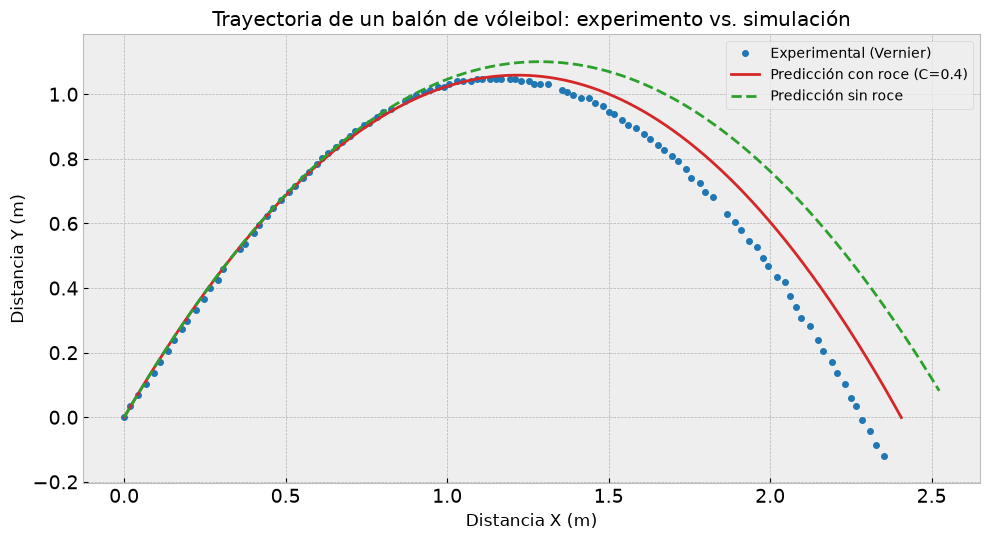

In [22]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(x_exp, y_exp, "o", ms=4, color="tab:blue", label="Experimental (Vernier)")
ax.plot(x_r, y_r, "-", lw=2, color="tab:red", label=f"Predicción con roce (C={C})")
ax.plot(x_s, y_s, "--", lw=2, color="tab:green", label="Predicción sin roce")
ax.set_xlabel("Distancia X (m)")
ax.set_ylabel("Distancia Y (m)")
ax.set_title("Trayectoria de un balón de vóleibol: experimento vs. simulación")
ax.set_aspect("equal", adjustable="datalim")
fontsize=16
ax.tick_params(axis="both", labelsize=14)
ax.legend(fontsize=13)
ax.legend()
fig.tight_layout()
plt.show()

## Convergencia temporal Euler

In [23]:
pasos = [0.004, 0.002, 0.001, 0.0005, 0.00025] #Pasos temporales que se evaluarán
diferencias = [] #lista donde se van a guardar las diferencias entre simulaciones

#Compara simulaciones con pasos temporales consecutivos
for i in range(len(pasos) - 1):
    dt1 = pasos[i]      # Paso temporal grande
    dt2 = pasos[i + 1]  # Paso temporal más pequeño
    _, x1, y1 = simular(vx0, vy0, t_max, con_roce=True, dt=dt1) #Simula la trayectoria con paso temporal grande
    _, x2, y2 = simular(vx0, vy0, t_max, con_roce=True, dt=dt2) #Simula la trayectoria con paso temporal pequeño
    n = min(len(x1), len(x2[::2])) #determina la cantidad de puntos que pueden compararse
    D_conv = np.sqrt(np.mean((x1[:n] - x2[::2][:n])**2 + (y1[:n] - y2[::2][:n])**2)) #Calcula la diferencia RMS entre las trayectorias
    
    diferencias.append(D_conv) #guarda la diferencia RMS
    print(f"dt = {dt1:.5f} vs {dt2:.5f} s: RMS = {D_conv:.6f} m") #muestra los pasos temporales comparados y su diferencia RMS

print("\nOrden de convergencia:")
for i in range(len(diferencias) - 1): #Compara las diferencias RMS obtenidas
    p = np.log2(diferencias[i] / diferencias[i + 1]) #calcula el orden de convergencia
    print(f"p = {p:.3f}") #muestra el resultado con 3 decimales

dt = 0.00400 vs 0.00200 s: RMS = 0.005045 m
dt = 0.00200 vs 0.00100 s: RMS = 0.002526 m
dt = 0.00100 vs 0.00050 s: RMS = 0.001262 m
dt = 0.00050 vs 0.00025 s: RMS = 0.000631 m

Orden de convergencia:
p = 0.998
p = 1.000
p = 1.000


## Propagación de errores y gráficos

### Incertidumbres


In [24]:
delta_d = 0.001 #incertidumbre diámetro voley
delta_C = 0.05  #incertidumbre coeficiente de arrastre voley (literatura)
delta_p = 2.0  #incertidumbre de píxeles 

#presión y temperatura usadas para estimar la incertidumbre de densidad del aire
P, delta_P = 100080.0, 10.0 
Temp_C, delta_T = 15.0, 1.0

delta_A = 2 * A * delta_d / D #calcula la incertidumbre del area transversal del balón
delta_rho = rho * np.hypot(delta_P / P, delta_T / (Temp_C + 273.15)) #estima la incertidumbre de la densidad del aire
delta_B = B * np.sqrt((delta_C / C)**2 + (delta_rho / rho)**2 + (delta_A / A)**2) #combina las variaciones consideradas para obtener delta B

##Incertidumbre de posiciones y velocidad inicial

err_S = np.sqrt(2) * delta_p / REFERENCIA_PIXELES #calcula la incertidumbre relativa de la escala
err_px = np.sqrt(2) * delta_p / PX_POR_M #convierte la incertidumbre de píxeles a metros

#calcula las incertidumbres de las posiciones experimentales
dx_exp = np.hypot(err_px, x_exp * err_S) 
dy_exp = np.hypot(err_px, y_exp * err_S)

#Obtiene las matrices de covarianza de los ajustes cuadráticos
cov_x = np.polyfit(t[:N], x_exp[:N], 2, cov=True)[1]
cov_y = np.polyfit(t[:N], y_exp[:N], 2, cov=True)[1]

#calcula las incertidumbres de las componentes de la velocidad inicial
dvx = np.sqrt(cov_x[1, 1])
dvy = np.sqrt(cov_y[1, 1])

v0 = np.hypot(vx0, vy0) #Calcula la magnitud de la velocidad inicial
dv0 = np.hypot(vx0 * dvx, vy0 * dvy) / v0 #calcula la incertidumbre de la rapidez inicial

print(f"Incertidumbre promedio X = {np.mean(dx_exp):.4f} m")
print(f"Incertidumbre promedio Y = {np.mean(dy_exp):.4f} m")
print(f"vx0 = {vx0:.3f} ± {dvx:.3f} m/s")
print(f"vy0 = {vy0:.3f} ± {dvy:.3f} m/s")


##Banda de incertidumbre de B

#simula las trayectorias con el valor máximo y mínimo de B
_, xb, yb = simular(vx0, vy0, t_max, b_val=B - delta_B)
_, xa, ya = simular(vx0, vy0, t_max, b_val=B + delta_B)

#Estima con interpolación las alturas en las mismas posiciones X
yb = np.interp(x_r, xb, yb, left=np.nan, right=np.nan)
ya = np.interp(x_r, xa, ya, left=np.nan, right=np.nan)

#Determina los límites inferior y superior de la banda
y_inf = np.minimum(yb, ya)
y_sup = np.maximum(yb, ya)

Incertidumbre promedio X = 0.0111 m
Incertidumbre promedio Y = 0.0096 m
vx0 = 2.713 ± 0.042 m/s
vy0 = 4.643 ± 0.050 m/s


### Error entre simulación y experimento

In [25]:
#Función para calcular el error RMS entre las simulaciones y trayectorias exp
def rmse_2d(ts, xs, ys):
    #interpola las posiciones simuladas en los tiempos experimentales
    xi = np.interp(t, ts, xs)
    yi = np.interp(t, ts, ys)
    return np.sqrt(np.mean((xi - x_exp)**2 + (yi - y_exp)**2)) #Calcula el RMSE bidimensional entre las posiciones simuladas y experimentales

print(f"B = {B:.6f} ± {delta_B:.6f} kg/m") #muestra el coef. de resistencia B y su variación
print(f"|v0| = {v0:.3f} ± {dv0:.3f} m/s") #muestra la rapidez inicial y su incertidumbre

#muestra los errores RMS de las simulaciones con y sin resistencia del aire
print(f"RMSE con roce = {rmse_2d(ts_r, x_r, y_r):.4f} m") 
print(f"RMSE sin roce = {rmse_2d(ts_s, x_s, y_s):.4f} m")

B = 0.007930 ± 0.000995 kg/m
|v0| = 5.377 ± 0.048 m/s
RMSE con roce = 0.0659 m
RMSE sin roce = 0.1358 m


### Gráficos

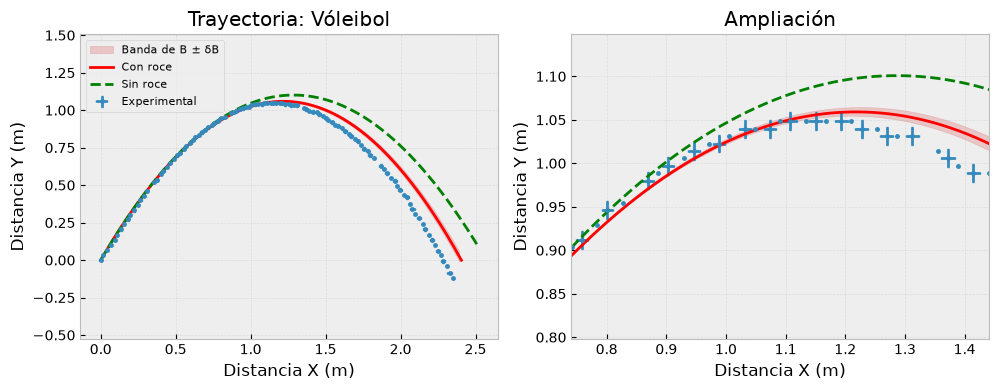

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax in axes:
    ax.fill_between(x_r, y_inf, y_sup, color="tab:red", alpha=0.2, label="Banda de B ± δB")
    ax.errorbar(x_exp, y_exp, xerr=dx_exp, yerr=dy_exp, fmt="o", ms=2.5, capsize=1, errorevery=2, label="Experimental")
    ax.plot(x_r, y_r, "r-", label="Con roce")
    ax.plot(x_s, y_s, "g--", label="Sin roce")
    ax.set(xlabel="Distancia X (m)", ylabel="Distancia Y (m)")
    ax.grid(alpha=0.3)

axes[0].set_title("Trayectoria: Vóleibol")
axes[0].set_aspect("equal", adjustable="datalim")
axes[0].legend(fontsize=8)
xm = x_exp[np.argmax(y_exp)]
ym = max(y_exp)
axes[1].set(xlim=(xm - 0.35, xm + 0.35), ylim=(ym - 0.25, ym + 0.10), title="Ampliación")
plt.tight_layout()
plt.show()